In [1]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

iris = load_iris()
df = pd.DataFrame(data =iris.data , columns= ["sepal_length", 'sepal_width', "petal_length", "petal_width"])
df.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [2]:
kmeans = KMeans(n_clusters=3, init="k-means++", max_iter=50, random_state=42)
kmeans.fit(df)


KMeans(max_iter=50, n_clusters=3, random_state=42)

In [3]:
df["target"] = iris.target
df["cluster"] = kmeans.labels_
res = df.groupby(["target", "cluster"])["sepal_length"].count()
res

target  cluster
0       1          50
1       0          48
        2           2
2       0          14
        2          36
Name: sepal_length, dtype: int64

In [4]:
from sklearn.decomposition import PCA
pca = PCA(n_components= 2)
pca_transformed = pca.fit_transform(iris.data)
df["pca_x"] = pca_transformed[: , 0]
df["pca_y"] = pca_transformed[: , 1]
df.head()


,sepal_length,sepal_width,petal_length,petal_width,target,cluster,pca_x,pca_y
0,5.1,3.5,1.4,0.2,0,1,-2.684126,0.319397
1,4.9,3.0,1.4,0.2,0,1,-2.714142,-0.177001
2,4.7,3.2,1.3,0.2,0,1,-2.888991,-0.144949
3,4.6,3.1,1.5,0.2,0,1,-2.745343,-0.318299
4,5.0,3.6,1.4,0.2,0,1,-2.728717,0.326755


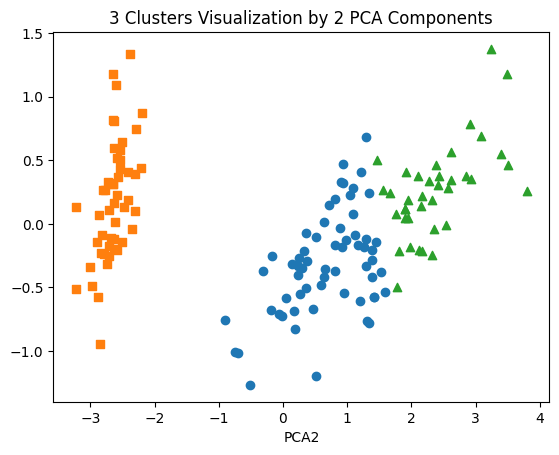

In [5]:
marker0_ind = df[df["cluster"] == 0].index
marker1_ind = df[df["cluster"] == 1].index
marker2_ind = df[df["cluster"] == 2].index

plt.scatter(x = df.loc[marker0_ind, "pca_x"],
            y = df.loc[marker0_ind, "pca_y"],
            marker = "o"
            )
plt.scatter(x = df.loc[marker1_ind, "pca_x"],
            y = df.loc[marker1_ind, "pca_y"],
            marker = "s"
            )
plt.scatter(x = df.loc[marker2_ind, "pca_x"],
            y = df.loc[marker2_ind, "pca_y"],
            marker = "^"
            )

plt.xlabel("PCA1")
plt.xlabel("PCA2")
plt.title("3 Clusters Visualization by 2 PCA Components")
plt.show() #클러스터 된게 분류보다 더 잘 나온다.(그래프에 겹치는 부분이 없다,,)

In [6]:
import numpy as np
import matplotlib.pyplot as pltfrom 
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples= 200, n_features= 2 , centers = 3 , cluster_std= 0.8 , random_state= 0)

print (X.shape, y.shape)

(200, 2) (200,)


In [7]:
unique, counts = np.unique(y, return_counts=True)
print(unique, counts)

[0 1 2] [67 67 66]


In [8]:
import pandas as pd
df = pd.DataFrame(data = X , columns= [ "ftr1", "ftr2"])
df["target"] = y
df.head()

,ftr1,ftr2,target
0,-1.692427,3.622025,2
1,0.697940,4.428867,0
2,1.100228,4.606317,0
3,-1.448724,3.384245,2
4,1.214861,5.364896,0


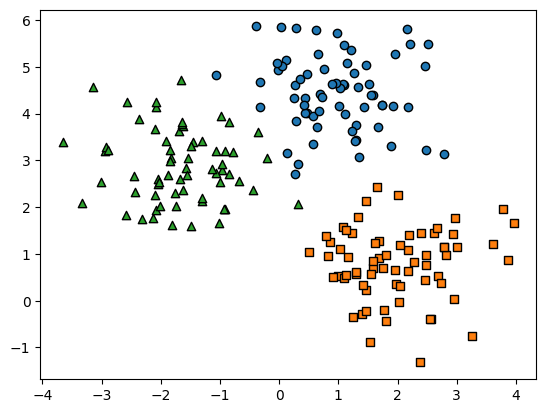

In [9]:
target_list = np.unique(y)
markers = ["o", "s", "^", "P", "D", "H", "x"]

for target in target_list :
    target_cluster = df[df["target"]==target]
    plt.scatter(x = target_cluster["ftr1"], y= target_cluster["ftr2"],
                edgecolors= "k", marker= markers[target]) 

plt.show()

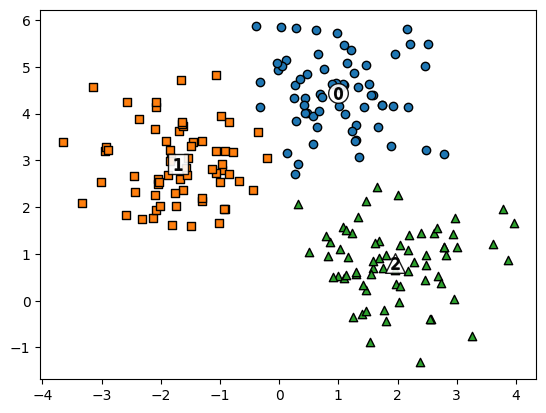

In [10]:
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    max_iter=200,
    random_state=0
)

cluster_labels = kmeans.fit_predict(X)
df["kmeans_label"] = cluster_labels

centers = kmeans.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers = ["o", "s", "^", "P", "D", "H", "x"]

for label in unique_labels:
    label_cluster = df[df["kmeans_label"] == label]
    center_x_y = centers[label]

    plt.scatter(
        x=label_cluster["ftr1"],
        y=label_cluster["ftr2"],
        edgecolors="k",
        marker=markers[label]
    )
    plt.scatter(
        x=center_x_y[0],
        y=center_x_y[1],
        s=200,
        color="white",
        alpha=0.9,
        edgecolors="k",
        marker=markers[label]
    )
    plt.scatter(
        x=center_x_y[0],
        y=center_x_y[1],
        s=70,
        color="k",
        alpha=0.9,
        edgecolors="k",
        marker=f"${label}$"
    )

In [11]:
df.groupby("target")["kmeans_label"].value_counts()

target  kmeans_label
0       0               66
        1                1
1       2               67
2       1               65
        2                1
Name: kmeans_label, dtype: int64